# Proyecto Integrador de Ciencia de Datos e IA — Entregable 2
## Preprocesamiento, ingeniería de variables, partición de datos y modelos base

**Universidad de La Salle — Maestría en Inteligencia Artificial — Ciencia de Datos**
Docente: Fabián Camilo Castro Riveros · Autor: Jairo Teófilo Araméndiz Pinzón

**Dataset:** *Medical Appointment No Shows* (Kaggle, `KaggleV2-May-2016.csv`, licencia CC BY-NC-SA 4.0).

Este cuaderno parte de los hallazgos del Entregable 1 y aplica, en este orden:

1. limpieza de registros inválidos y análisis del mecanismo de falta antes de imputar;
2. tratamiento razonado de valores atípicos;
3. creación de variables derivadas con base en el dominio;
4. partición entrenamiento / validación / prueba estratificada y agrupada por paciente;
5. codificación y escalamiento dentro de *pipelines* ajustados solo con entrenamiento;
6. revisión del desbalance de clases;
7. modelos base de clasificación y regresión, más la preparación de la matriz para *clustering*.

**Cómo ejecutarlo:** en Colab basta con subir `KaggleV2-May-2016.csv` al panel de archivos (o aceptar la ventana de carga que aparece al ejecutar la celda 1). En local, el archivo puede estar en `../data/`, `./data/` o en la misma carpeta del cuaderno.

## 0. Configuración y carga del archivo

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, TargetEncoder
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             r2_score, mean_squared_error, mean_absolute_error, confusion_matrix)

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
SEMILLA = 42
print('scikit-learn', sklearn.__version__)

NOMBRE = 'KaggleV2-May-2016.csv'
candidatos = [Path('../data') / NOMBRE, Path('data') / NOMBRE, Path(NOMBRE), Path('/content') / NOMBRE]
RUTA = next((p for p in candidatos if p.exists()), None)
if RUTA is None:
    try:
        from google.colab import files  # solo existe en Colab
        print('Seleccione el archivo', NOMBRE)
        files.upload()
        RUTA = Path(NOMBRE)
    except ImportError:
        raise FileNotFoundError(f'No se encontró {NOMBRE}. Colóquelo junto al cuaderno o en ../data/')

SALIDA = RUTA.parent / 'procesado'
SALIDA.mkdir(exist_ok=True)
RES = {}
raw = pd.read_csv(RUTA)
print('Archivo:', RUTA, '| dimensiones:', raw.shape)

scikit-learn 1.9.1


Archivo: ../data/KaggleV2-May-2016.csv | dimensiones: (110527, 14)


In [2]:
mapa = {'PatientId': 'id_paciente', 'AppointmentID': 'id_cita', 'Gender': 'sexo',
        'ScheduledDay': 'fecha_agendamiento', 'AppointmentDay': 'fecha_cita', 'Age': 'edad',
        'Neighbourhood': 'barrio', 'Scholarship': 'bolsa_familia', 'Hipertension': 'hipertension',
        'Diabetes': 'diabetes', 'Alcoholism': 'alcoholismo', 'Handcap': 'discapacidad',
        'SMS_received': 'sms_recibido', 'No-show': 'no_asistio'}
df = raw.rename(columns=mapa).copy()
df['id_paciente'] = df['id_paciente'].astype('int64').astype(str)   # identificador, no número
df['fecha_agendamiento'] = pd.to_datetime(df['fecha_agendamiento'], utc=True)
df['fecha_cita'] = pd.to_datetime(df['fecha_cita'], utc=True)
df['inasistencia'] = (df['no_asistio'] == 'Yes').astype(int)
df['dias_espera'] = (df['fecha_cita'].dt.normalize() - df['fecha_agendamiento'].dt.normalize()).dt.days
RES['filas_iniciales'] = len(df)
df.head(3)

,id_paciente,id_cita,sexo,fecha_agendamiento,fecha_cita,edad,barrio,bolsa_familia,hipertension,diabetes,alcoholismo,discapacidad,sms_recibido,no_asistio,inasistencia,dias_espera
0,29872499824296,5642903,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,0,0
1,558997776694438,5642503,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,0,0
2,4262962299951,5642549,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,0,0


## 1. Limpieza de datos

### 1.1 Registros con eventos imposibles (eliminación)
El Entregable 1 identificó 1 registro con edad negativa y 5 citas con fecha anterior a su agendamiento. Son errores de registro sin valor recuperable: no existe una edad o una espera "verdadera" que se pueda inferir de las demás columnas, y el volumen es despreciable (6 de 110.527 registros). Se eliminan.

In [3]:
invalidos = (df.edad < 0) | (df.dias_espera < 0)
RES['eliminados_invalidos'] = int(invalidos.sum())
print('Registros eliminados:', invalidos.sum())
df = df.loc[~invalidos].reset_index(drop=True)

Registros eliminados: 6


### 1.2 Edades no plausibles: análisis del mecanismo de falta antes de imputar
El dataset no tiene celdas vacías, pero sí valores que deben tratarse como faltantes: edades de 115 años, por encima de la persona más longeva registrada en el momento de la recolección. Las de 102 años son plausibles y se conservan. Antes de decidir cómo tratarlas se revisa a quién pertenecen y si se asocian con otras variables.

In [4]:
edad_no_plausible = df.edad > 110
print(df.loc[edad_no_plausible, ['id_paciente', 'edad', 'sexo', 'barrio', 'hipertension', 'no_asistio']])
print('\nPacientes distintos afectados:', df.loc[edad_no_plausible, 'id_paciente'].nunique())

# ¿La falta se asocia con variables observadas? (comparación de proporciones; n muy pequeño)
comp = pd.DataFrame({
    'con edad 115': df.loc[edad_no_plausible, ['inasistencia', 'sms_recibido', 'dias_espera']].mean(),
    'resto': df.loc[~edad_no_plausible, ['inasistencia', 'sms_recibido', 'dias_espera']].mean()})
RES['edad_115'] = {'registros': int(edad_no_plausible.sum()), 'pacientes': int(df.loc[edad_no_plausible, 'id_paciente'].nunique())}
comp.round(3)

           id_paciente  edad sexo      barrio  hipertension no_asistio
63910   31963211613981   115    F  ANDORINHAS             0        Yes
63913   31963211613981   115    F  ANDORINHAS             0        Yes
68124   31963211613981   115    F  ANDORINHAS             0        Yes
76279   31963211613981   115    F  ANDORINHAS             0         No
97661  748234579244724   115    F    SÃO JOSÉ             1         No

Pacientes distintos afectados: 2


,con edad 115,resto
inasistencia,0.6,0.202
sms_recibido,0.2,0.321
dias_espera,11.8,10.184


**Diagnóstico del mecanismo.** Los 5 registros pertenecen a solo 2 pacientes, y 4 de ellos a uno solo. El error, por tanto, no está repartido al azar entre citas: viene del dato de edad guardado en la ficha del paciente. Eso descarta un mecanismo MCAR puro a nivel de cita. Tampoco hay forma de saber si la edad real depende de su propio valor (MNAR), porque no existe otra fuente para contrastarla. Con 5 casos (0,005 %) ninguna prueba estadística tiene potencia, de modo que la comparación anterior es solo descriptiva.

**Decisión.** Se marca la edad como faltante (`NaN`) y se imputa con la **mediana del conjunto de entrenamiento** dentro del *pipeline*. Se prefiere la mediana porque la edad no es normal (moda en 0, curtosis negativa) y porque, con tan pocos casos, métodos como `KNNImputer` o `IterativeImputer` no cambiarían el resultado y añadirían complejidad sin beneficio. Se conserva la cita porque el resto de la información (espera, SMS, asistencia) es válida.

In [5]:
df.loc[edad_no_plausible, 'edad'] = np.nan
print('Edades marcadas como faltantes:', df.edad.isna().sum())

Edades marcadas como faltantes: 5


### 1.3 Duplicados lógicos
El EDA encontró registros con el mismo paciente, la misma fecha de cita y el mismo instante de agendamiento, pero con distinto `id_cita`.

In [6]:
clave = ['id_paciente', 'fecha_cita', 'fecha_agendamiento']
grupos = df[df.duplicated(clave, keep=False)].groupby(clave)
tam = grupos.size(); distinto = grupos.inasistencia.nunique()
RES['dup_grupos'] = int(len(tam)); RES['dup_grupos_resultado_distinto'] = int((distinto > 1).sum())
print('Grupos:', len(tam), '| tamaño de grupo:', tam.value_counts().to_dict())
print('Grupos donde el resultado (asistió / no asistió) difiere:', (distinto > 1).sum())

Grupos: 1275 | tamaño de grupo: {2: 1223, 3: 50, 7: 1, 6: 1}
Grupos donde el resultado (asistió / no asistió) difiere: 29


**Decisión.** Se conservan. En 29 grupos el resultado difiere entre registros, lo que indica que al menos parte de ellos son citas distintas (por ejemplo, dos profesionales el mismo día) y no copias. Como el dataset no trae especialidad ni profesional, no hay criterio objetivo para descartar uno de cada par. Para que estos registros no generen fuga de información, la partición se hace **agrupada por paciente**: todas las citas de un paciente quedan en el mismo subconjunto. Además se crea la variable `citas_mismo_dia`, que convierte esta situación en información para el modelo.

## 2. Ingeniería de variables
Todas las variables se construyen con información disponible antes de la cita. Ninguna usa el resultado de la cita que se quiere predecir.

| Variable | Justificación de dominio |
|---|---|
| `dias_espera` | Tiempo entre el agendamiento y la cita; fue el factor más asociado a la inasistencia en el EDA (V de Cramér 0,29). También es el objetivo de regresión. |
| `cita_mismo_dia` | Las citas del mismo día tienen inasistencia cercana al 5 %; el efecto no es lineal respecto a la espera. |
| `dia_semana_cita`, `hora_agendamiento`, `dia_semana_agendamiento` | Patrones de calendario y de canal de atención (horario del agendamiento). |
| `n_condiciones_cronicas` | Suma de hipertensión, diabetes y alcoholismo: aproxima la carga de enfermedad y la necesidad de control. |
| `grupo_etario` | Ciclo vital; el EDA mostró la mayor inasistencia en 13-18 años y la menor en mayores de 60. |
| `citas_mismo_dia` | Número de citas del paciente en la misma fecha (ver 1.3). |
| `citas_previas`, `inasistencias_previas`, `tasa_inasistencia_previa` | Historial del paciente en fechas **anteriores** a la cita. La literatura señala la inasistencia previa como uno de los mejores predictores (Dantas et al., 2018). |

In [7]:
df = df.sort_values(['id_paciente', 'fecha_cita', 'fecha_agendamiento']).reset_index(drop=True)
df['cita_mismo_dia'] = (df.dias_espera == 0).astype(int)
dias = {0: 'lunes', 1: 'martes', 2: 'miercoles', 3: 'jueves', 4: 'viernes', 5: 'sabado', 6: 'domingo'}
df['dia_semana_cita'] = df.fecha_cita.dt.dayofweek.map(dias)
df['dia_semana_agendamiento'] = df.fecha_agendamiento.dt.dayofweek.map(dias)
df['hora_agendamiento'] = df.fecha_agendamiento.dt.hour
df['n_condiciones_cronicas'] = df[['hipertension', 'diabetes', 'alcoholismo']].sum(axis=1)
df['grupo_etario'] = pd.cut(df.edad, [-1, 12, 18, 35, 60, 200], labels=['0-12', '13-18', '19-35', '36-60', '60+']).astype(str)
df.loc[df.edad.isna(), 'grupo_etario'] = np.nan
df['citas_mismo_dia'] = df.groupby(['id_paciente', 'fecha_cita']).id_cita.transform('count')

# Historial: se agrega por paciente y fecha, y se acumula SOLO lo ocurrido en fechas anteriores
por_dia = (df.groupby(['id_paciente', 'fecha_cita'])
             .agg(n=('id_cita', 'count'), ina=('inasistencia', 'sum')).reset_index())
g = por_dia.groupby('id_paciente')
por_dia['citas_previas'] = g.n.cumsum() - por_dia.n
por_dia['inasistencias_previas'] = g.ina.cumsum() - por_dia.ina
df = df.merge(por_dia[['id_paciente', 'fecha_cita', 'citas_previas', 'inasistencias_previas']],
              on=['id_paciente', 'fecha_cita'], how='left')
df['tasa_inasistencia_previa'] = np.where(df.citas_previas > 0, df.inasistencias_previas / df.citas_previas.replace(0, 1), np.nan)

# Comprobación: la primera fecha de cada paciente no puede tener historial
primera = df.groupby('id_paciente').fecha_cita.transform('min') == df.fecha_cita
assert (df.loc[primera, 'citas_previas'] == 0).all()
RES['pct_con_historial'] = float((df.citas_previas > 0).mean() * 100)
print(f"Citas con historial previo: {RES['pct_con_historial']:.1f} %")
df[['dias_espera', 'cita_mismo_dia', 'n_condiciones_cronicas', 'citas_mismo_dia', 'citas_previas', 'inasistencias_previas', 'tasa_inasistencia_previa']].describe().round(2)

Citas con historial previo: 40.0 %


,dias_espera,cita_mismo_dia,n_condiciones_cronicas,citas_mismo_dia,citas_previas,inasistencias_previas,tasa_inasistencia_previa
count,110521.00,110521.00,110521.0,110521.00,110521.00,110521.00,44233.00
mean,10.18,0.35,0.3,1.19,1.18,0.18,0.20
std,15.26,0.48,0.6,0.52,3.80,0.61,0.34
min,0.00,0.00,0.0,1.00,0.00,0.00,0.00
25%,0.00,0.00,0.0,1.00,0.00,0.00,0.00
50%,4.00,0.00,0.0,1.00,0.00,0.00,0.00
75%,15.00,1.00,0.0,1.00,1.00,0.00,0.33
max,179.00,1.00,3.0,10.00,83.00,15.00,1.00


`tasa_inasistencia_previa` queda vacía en la primera cita de cada paciente: no es un dato perdido sino un paciente sin historial (falta estructural, determinada por `citas_previas = 0`). Se imputa con la tasa media de entrenamiento y se acompaña de un indicador de falta (`add_indicator=True`), de modo que el modelo distingue "sin historial" de "historial con tasa promedio".

In [8]:
ina_hist = df.groupby(pd.cut(df.inasistencias_previas, [-1, 0, 1, 100], labels=['0', '1', '2+'])).inasistencia.agg(['mean', 'count'])
ina_hist['mean'] = (ina_hist['mean'] * 100).round(1)
print('Inasistencia (%) según inasistencias previas del paciente:'); print(ina_hist)
RES['ina_por_historial'] = ina_hist['mean'].to_dict()

Inasistencia (%) según inasistencias previas del paciente:
                       mean  count
inasistencias_previas             
0                      19.2  96407
1                      25.1  10474
2+                     32.1   3640


## 3. Tratamiento de valores atípicos
- **Edad:** tras el paso 1.2 no quedan atípicos por regla IQR.
- **Días de espera:** la cola derecha (hasta 179 días) es real; eliminarla quitaría las citas lejanas, que son las de mayor ausentismo. Se usa **recorte por percentiles (winsorización)** al percentil 99, con el umbral calculado **solo en entrenamiento**, cuando la espera es predictor. Cuando la espera es objetivo de regresión se evalúa además la transformación `log(1 + x)`.
- **Variables de conteo** (`citas_mismo_dia`, `citas_previas`, `inasistencias_previas`): pocos pacientes concentran muchas citas; se aplica la misma winsorización.

In [9]:
class Winsorizador(BaseEstimator, TransformerMixin):
    """Recorta cada columna a los percentiles [inf, sup] aprendidos en fit (solo entrenamiento)."""
    def __init__(self, inf=0.0, sup=0.99):
        self.inf, self.sup = inf, sup
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lim_inf_ = np.nanquantile(X, self.inf, axis=0)
        self.lim_sup_ = np.nanquantile(X, self.sup, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lim_inf_, self.lim_sup_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features)

## 4. Partición de datos
Se usa `StratifiedGroupKFold` con 20 particiones: 3 forman la **prueba** (≈15 %), 3 la **validación** (≈15 %) y 14 el **entrenamiento** (≈70 %). La estratificación conserva la proporción de inasistencia en los tres subconjuntos, y el agrupamiento por paciente impide que citas de una misma persona queden repartidas, lo que inflaría las métricas.

In [10]:
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEMILLA)
df['fold'] = -1
for k, (_, idx) in enumerate(sgkf.split(df, df.inasistencia, groups=df.id_paciente)):
    df.loc[idx, 'fold'] = k
df['conjunto'] = np.select([df.fold < 3, df.fold < 6], ['prueba', 'validacion'], 'entrenamiento')

resumen = df.groupby('conjunto').agg(citas=('id_cita', 'count'), pacientes=('id_paciente', 'nunique'),
                                     pct_inasistencia=('inasistencia', 'mean'), espera_media=('dias_espera', 'mean'))
resumen['pct_citas'] = resumen.citas / len(df) * 100
resumen['pct_inasistencia'] *= 100
# Verificación: ningún paciente en dos subconjuntos
assert df.groupby('id_paciente').conjunto.nunique().max() == 1
RES['particion'] = resumen.round(3).to_dict('index')
resumen.round(2)

,citas,pacientes,pct_inasistencia,espera_media,pct_citas
conjunto,,,,,
entrenamiento,77361,43485,20.19,10.20,70.0
prueba,16583,9437,20.20,10.16,15.0
validacion,16577,9376,20.18,10.14,15.0


## 5. Codificación y escalamiento sin fuga de información
Cada transformación se declara dentro de un `ColumnTransformer` y solo se ajusta con `fit` sobre entrenamiento; validación y prueba se transforman con lo aprendido.

| Grupo | Variables | Tratamiento |
|---|---|---|
| Numéricas continuas | edad, dias_espera, hora_agendamiento, citas_previas, inasistencias_previas, citas_mismo_dia | Imputación por mediana → winsorización P99 → `StandardScaler` |
| Tasa de historial | tasa_inasistencia_previa | Imputación por media + indicador de falta → `StandardScaler` |
| Binarias y ordinal | sexo (F=1), bolsa_familia, hipertension, diabetes, alcoholismo, discapacidad (0-4), sms_recibido, cita_mismo_dia, n_condiciones_cronicas | Se dejan en su escala original (ya son 0/1 o conteos pequeños ordenados) |
| Nominales de baja cardinalidad | dia_semana_cita, dia_semana_agendamiento, grupo_etario | `OneHotEncoder(handle_unknown='ignore')` |
| Nominal de alta cardinalidad | barrio (81 categorías, varias con muy pocas citas) | `TargetEncoder` con validación cruzada interna, que evita que cada registro use su propio resultado |

**Variables excluidas por fuga:** para la regresión de `dias_espera` se excluye `sms_recibido` (el SMS solo se envía cuando la espera es de 3 días o más, así que revela el objetivo), `cita_mismo_dia` (es una función directa del objetivo) y el mes de agendamiento (como todas las citas son de abril a junio de 2016, un agendamiento en noviembre implica una espera larga por construcción del dataset).

In [11]:
df['sexo_f'] = (df.sexo == 'F').astype(int)
NUM = ['edad', 'dias_espera', 'hora_agendamiento', 'citas_previas', 'inasistencias_previas', 'citas_mismo_dia']
TASA = ['tasa_inasistencia_previa']
BIN = ['sexo_f', 'bolsa_familia', 'hipertension', 'diabetes', 'alcoholismo', 'discapacidad', 'sms_recibido', 'cita_mismo_dia', 'n_condiciones_cronicas']
CAT = ['dia_semana_cita', 'dia_semana_agendamiento', 'grupo_etario']
ALTA = ['barrio']

def preprocesador(num, tasa, binarias, cat, alta, tipo_objetivo):
    pasos = [('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('win', Winsorizador(0, .99)), ('esc', StandardScaler())]), num),
             ('bin', 'passthrough', binarias),
             ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
             ('alta', TargetEncoder(target_type=tipo_objetivo, random_state=SEMILLA), alta)]
    if tasa:
        pasos.insert(1, ('tasa', Pipeline([('imp', SimpleImputer(strategy='mean', add_indicator=True)), ('esc', StandardScaler())]), tasa))
    return ColumnTransformer(pasos, verbose_feature_names_out=False)

ent, val, pru = (df[df.conjunto == c] for c in ['entrenamiento', 'validacion', 'prueba'])
y_ent, y_val, y_pru = ent.inasistencia, val.inasistencia, pru.inasistencia

prep_clf = preprocesador(NUM, TASA, BIN, CAT, ALTA, 'binary')
X_ent = prep_clf.fit_transform(ent, y_ent)      # ajuste SOLO con entrenamiento
X_val = prep_clf.transform(val); X_pru = prep_clf.transform(pru)
nombres = prep_clf.get_feature_names_out()
print('Matriz de entrenamiento:', X_ent.shape, '| variables:', len(nombres))
print('Media de las numéricas escaladas en entrenamiento (≈0):', np.round(X_ent[:, :len(NUM)].mean(0), 3))
print('Media de las mismas en validación (no tiene por qué ser 0):', np.round(X_val[:, :len(NUM)].mean(0), 3))
win = prep_clf.named_transformers_['num'].named_steps['win']
RES['umbral_p99_entrenamiento'] = dict(zip(NUM, np.round(win.lim_sup_, 2).tolist()))
RES['n_variables_clf'] = int(len(nombres))
print('Umbrales P99 aprendidos en entrenamiento:', RES['umbral_p99_entrenamiento'])

Matriz de entrenamiento: (77361, 35) | variables: 35
Media de las numéricas escaladas en entrenamiento (≈0): [ 0.  0. -0.  0. -0.  0.]
Media de las mismas en validación (no tiene por qué ser 0): [ 0.013 -0.003 -0.002 -0.02  -0.03   0.001]
Umbrales P99 aprendidos en entrenamiento: {'edad': 86.0, 'dias_espera': 68.0, 'hora_agendamiento': 18.0, 'citas_previas': 14.0, 'inasistencias_previas': 3.0, 'citas_mismo_dia': 3.0}


## 6. Desbalance de clases
La clase positiva (no asistió) representa cerca del 20 % de los registros, una relación aproximada de 4 a 1. No es un desbalance severo, por lo que no se generan datos sintéticos. Se usa `class_weight='balanced'` en la regresión logística, que pondera más los errores sobre la clase minoritaria sin alterar la distribución de los datos. A modo de contraste se muestra el efecto de SMOTE aplicado **solo a entrenamiento**; nunca se aplica a validación ni a prueba.

In [12]:
print('Proporción de inasistencia por conjunto (%):', {c: round(s.mean() * 100, 2) for c, s in [('ent', y_ent), ('val', y_val), ('pru', y_pru)]})
try:
    from imblearn.over_sampling import SMOTE
    Xs, ys = SMOTE(random_state=SEMILLA).fit_resample(X_ent, y_ent)
    print(f'SMOTE (solo ilustrativo): entrenamiento pasa de {len(y_ent):,} a {len(ys):,} filas, positivos {ys.mean():.0%}')
    RES['smote_disponible'] = True
except ImportError:
    print('imbalanced-learn no está instalado; se continúa con class_weight.')
    RES['smote_disponible'] = False

Proporción de inasistencia por conjunto (%): {'ent': np.float64(20.19), 'val': np.float64(20.18), 'pru': np.float64(20.2)}


SMOTE (solo ilustrativo): entrenamiento pasa de 77,361 a 123,484 filas, positivos 50%


## 7. Modelos base (baseline)

### 7.1 Clasificación de la inasistencia
Se comparan tres referencias: un clasificador trivial que siempre predice la clase mayoritaria, uno que predice al azar respetando la proporción de clases y una regresión logística con todas las variables preprocesadas. La métrica principal es el **AUC-ROC** y el **F1 de la clase positiva**, porque la exactitud premia al modelo que nunca predice inasistencia.

In [13]:
def metricas_clf(modelo, X, y):
    pred = modelo.predict(X)
    prob = modelo.predict_proba(X)[:, 1]
    return {'exactitud': accuracy_score(y, pred), 'precision': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred), 'F1': f1_score(y, pred), 'AUC_ROC': roc_auc_score(y, prob)}

modelos_clf = {
    'Dummy (mayoritaria)': DummyClassifier(strategy='most_frequent'),
    'Dummy (estratificado)': DummyClassifier(strategy='stratified', random_state=SEMILLA),
    'Logística sin ponderar': LogisticRegression(max_iter=2000),
    'Logística class_weight=balanced': LogisticRegression(max_iter=2000, class_weight='balanced'),
}
filas = []
for nombre, m in modelos_clf.items():
    m.fit(X_ent, y_ent)
    for conj, X, y in [('validación', X_val, y_val), ('prueba', X_pru, y_pru)]:
        filas.append({'modelo': nombre, 'conjunto': conj, **metricas_clf(m, X, y)})
base_clf = pd.DataFrame(filas).set_index(['modelo', 'conjunto'])
RES['baseline_clf'] = {f'{a} | {b}': v for (a, b), v in base_clf.round(4).to_dict('index').items()}
base_clf.round(3)

exactitud  precision  recall     F1  AUC_ROC
modelo                          conjunto                                                
Dummy (mayoritaria)             validación      0.798      0.000   0.000  0.000    0.500
                                prueba          0.798      0.000   0.000  0.000    0.500
Dummy (estratificado)           validación      0.675      0.193   0.193  0.193    0.495
                                prueba          0.675      0.194   0.194  0.194    0.495
Logística sin ponderar          validación      0.798      0.487   0.023  0.043    0.733
                                prueba          0.796      0.418   0.021  0.040    0.730
Logística class_weight=balanced validación      0.592      0.310   0.830  0.451    0.733
                                prueba          0.591      0.309   0.825  0.449    0.729

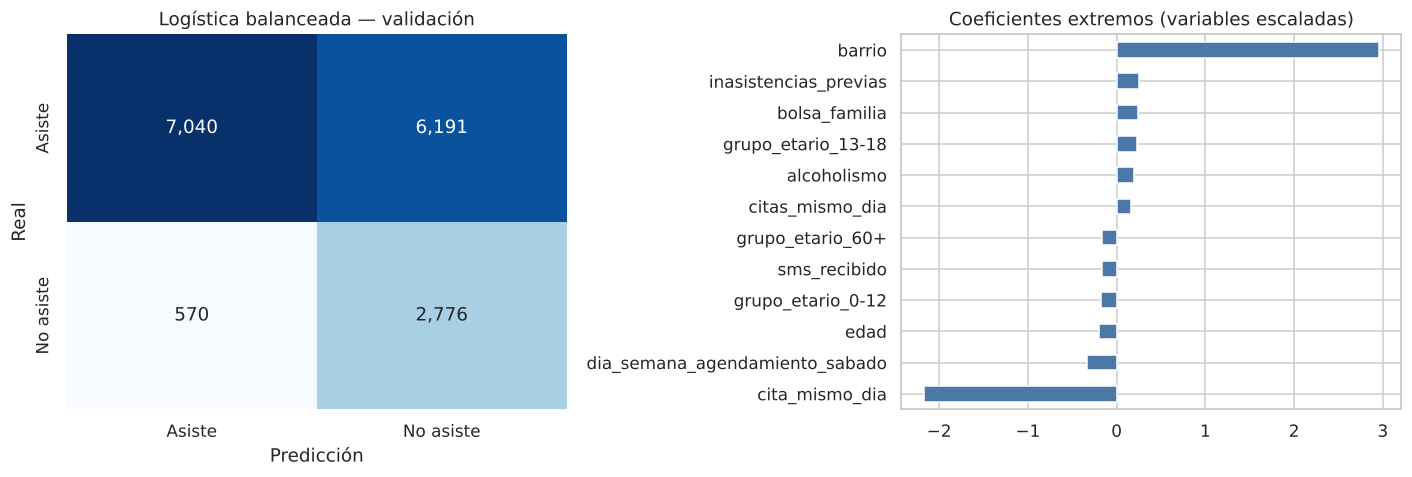

In [14]:
log_bal = modelos_clf['Logística class_weight=balanced']
cm = confusion_matrix(y_val, log_bal.predict(X_val))
coef = pd.Series(log_bal.coef_[0], index=nombres).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', cbar=False, ax=ax[0],
            xticklabels=['Asiste', 'No asiste'], yticklabels=['Asiste', 'No asiste'])
ax[0].set_xlabel('Predicción'); ax[0].set_ylabel('Real'); ax[0].set_title('Logística balanceada — validación')
pd.concat([coef.head(6), coef.tail(6)]).plot.barh(ax=ax[1], color='#4c78a8'); ax[1].set_title('Coeficientes extremos (variables escaladas)')
plt.tight_layout(); plt.show()
RES['coef_top'] = pd.concat([coef.head(5), coef.tail(5)]).round(3).to_dict()

### 7.2 Regresión de los días de espera
Referencias: un modelo que predice siempre la media de entrenamiento y una **regresión lineal simple** con un solo predictor. Como predictor se elige, entre las variables permitidas, la de mayor correlación de Spearman con la espera en entrenamiento. Se reporta además una regresión lineal con todas las variables permitidas, como referencia adicional para la Fase 3.

In [15]:
NUM_R = ['edad', 'hora_agendamiento', 'citas_previas', 'inasistencias_previas', 'citas_mismo_dia']
BIN_R = ['sexo_f', 'bolsa_familia', 'hipertension', 'diabetes', 'alcoholismo', 'discapacidad', 'n_condiciones_cronicas']
CAT_R = ['dia_semana_agendamiento', 'grupo_etario']   # el día de la cita se excluye: también depende de la espera
r_ent, r_val, r_pru = ent.dias_espera, val.dias_espera, pru.dias_espera

cands = ent[NUM_R + BIN_R].corrwith(ent.dias_espera, method='spearman').abs().sort_values(ascending=False)
mejor = cands.index[0]
RES['regresion_predictor_simple'] = mejor; RES['spearman_predictores_espera'] = cands.round(3).to_dict()
print('Correlación |Spearman| con la espera (entrenamiento):'); print(cands.round(3))

def metricas_reg(y, p):
    return {'R2': r2_score(y, p), 'RMSE': mean_squared_error(y, p) ** 0.5, 'MAE': mean_absolute_error(y, p)}

simple = Pipeline([('imp', SimpleImputer(strategy='median')), ('lr', LinearRegression())])
prep_reg = preprocesador(NUM_R, [], BIN_R, CAT_R, ALTA, 'continuous')
multiple = Pipeline([('prep', prep_reg), ('lr', LinearRegression())])
multiple_log = Pipeline([('prep', preprocesador(NUM_R, [], BIN_R, CAT_R, ALTA, 'continuous')), ('lr', LinearRegression())])

filas = []
media = DummyRegressor(strategy='mean').fit(ent[[mejor]], r_ent)
simple.fit(ent[[mejor]], r_ent)
multiple.fit(ent, r_ent)
multiple_log.fit(ent, np.log1p(r_ent))
for conj, d, y in [('validación', val, r_val), ('prueba', pru, r_pru)]:
    filas.append({'modelo': 'Dummy (media)', 'conjunto': conj, **metricas_reg(y, media.predict(d[[mejor]]))})
    filas.append({'modelo': f'Lineal simple ({mejor})', 'conjunto': conj, **metricas_reg(y, simple.predict(d[[mejor]]))})
    filas.append({'modelo': 'Lineal múltiple', 'conjunto': conj, **metricas_reg(y, multiple.predict(d))})
    filas.append({'modelo': 'Lineal múltiple, objetivo log(1+x)', 'conjunto': conj, **metricas_reg(y, np.expm1(multiple_log.predict(d)))})
base_reg = pd.DataFrame(filas).set_index(['modelo', 'conjunto'])
RES['baseline_reg'] = {f'{a} | {b}': v for (a, b), v in base_reg.round(4).to_dict('index').items()}
base_reg.round(3)

Correlación |Spearman| con la espera (entrenamiento):
hora_agendamiento         0.125
citas_mismo_dia           0.066
alcoholismo               0.042
sexo_f                    0.041
citas_previas             0.036
edad                      0.033
discapacidad              0.032
bolsa_familia             0.024
n_condiciones_cronicas    0.022
diabetes                  0.018
hipertension              0.009
inasistencias_previas     0.001
dtype: float64


,,R2,RMSE,MAE
modelo,conjunto,,,
Dummy (media),validación,-0.000,15.211,10.982
Lineal simple (hora_agendamiento),validación,0.005,15.174,10.923
Lineal múltiple,validación,0.079,14.594,10.574
"Lineal múltiple, objetivo log(1+x)",validación,-0.133,16.193,9.402
Dummy (media),prueba,-0.000,15.162,10.902
Lineal simple (hora_agendamiento),prueba,0.009,15.094,10.831
Lineal múltiple,prueba,0.077,14.568,10.529
"Lineal múltiple, objetivo log(1+x)",prueba,-0.133,16.138,9.377


## 8. Preparación de la matriz para *clustering*
La segmentación se hace a nivel de paciente, con variables agregadas sobre el periodo completo. Como es un problema no supervisado no hay conjunto de prueba, pero sí se escala, porque K-Means y DBSCAN usan distancias. Se usa `RobustScaler` porque varias variables tienen colas largas (número de citas, espera media), y `log(1 + x)` en los conteos.

In [16]:
pac = df.groupby('id_paciente').agg(edad=('edad', 'median'), n_citas=('id_cita', 'count'),
                                    tasa_inasistencia=('inasistencia', 'mean'), espera_media=('dias_espera', 'mean'),
                                    n_condiciones_cronicas=('n_condiciones_cronicas', 'max'), prop_sms=('sms_recibido', 'mean'),
                                    bolsa_familia=('bolsa_familia', 'max'))
pac['edad'] = pac.edad.fillna(pac.edad.median())
pac['log_n_citas'] = np.log1p(pac.n_citas); pac['log_espera_media'] = np.log1p(pac.espera_media)
VARS_CLUSTER = ['edad', 'log_n_citas', 'tasa_inasistencia', 'log_espera_media', 'n_condiciones_cronicas', 'prop_sms']
X_cluster = pd.DataFrame(RobustScaler().fit_transform(pac[VARS_CLUSTER]), columns=VARS_CLUSTER, index=pac.index)
RES['cluster'] = {'pacientes': int(len(pac)), 'variables': VARS_CLUSTER}
print('Matriz de clustering:', X_cluster.shape)
X_cluster.describe().round(2)

Matriz de clustering: (62298, 6)


,edad,log_n_citas,tasa_inasistencia,log_espera_media,n_condiciones_cronicas,prop_sms
count,62298.00,62298.00,62298.00,62298.00,62298.00,62298.00
mean,0.02,0.60,0.59,-0.05,0.29,0.50
std,0.60,0.89,1.05,0.46,0.59,0.63
min,-0.92,0.00,0.00,-0.65,0.00,0.00
25%,-0.49,0.00,0.00,-0.65,0.00,0.00
50%,0.00,0.00,0.00,0.00,0.00,0.00
75%,0.51,1.00,1.00,0.35,0.00,1.00
max,1.69,9.36,3.00,1.16,3.00,1.50


## 9. Exportación de los conjuntos procesados

In [17]:
cols = ['id_cita', 'id_paciente', 'conjunto', 'inasistencia', 'dias_espera'] + NUM[:1] + NUM[2:] + TASA + BIN + CAT + ALTA
df[cols].to_csv(SALIDA / 'citas_con_variables.csv', index=False)
for nombre, X, y in [('entrenamiento', X_ent, y_ent), ('validacion', X_val, y_val), ('prueba', X_pru, y_pru)]:
    out = pd.DataFrame(X, columns=nombres); out['inasistencia'] = y.values
    out.to_csv(SALIDA / f'clf_{nombre}.csv', index=False)
pac.join(X_cluster.add_suffix('_esc')).to_csv(SALIDA / 'pacientes_clustering.csv')
RES['filas_finales'] = int(len(df))
(SALIDA / 'resultados_fase2.json').write_text(json.dumps(RES, indent=2, ensure_ascii=False, default=str))
print('Archivos guardados en', SALIDA.resolve()); print(sorted(p.name for p in SALIDA.iterdir()))

Archivos guardados en /home/claude/ent1/data/procesado
['citas_con_variables.csv', 'clf_entrenamiento.csv', 'clf_prueba.csv', 'clf_validacion.csv', 'pacientes_clustering.csv', 'resultados_fase2.json']


## 10. Síntesis
- **Limpieza:** se eliminaron 6 registros con eventos imposibles. Las 5 edades de 115 años se trataron como faltantes tras analizar su origen (2 pacientes) y se imputaron con la mediana de entrenamiento. Los duplicados lógicos se conservaron y se neutralizó su riesgo con la partición agrupada por paciente.
- **Atípicos:** la espera y los conteos se recortan al P99 aprendido en entrenamiento; para la espera como objetivo se compara la escala original con `log(1 + x)`.
- **Variables derivadas:** 11 variables nuevas, entre ellas el historial de inasistencias del paciente calculado solo con fechas anteriores.
- **Sin fuga de información:** imputación, winsorización, escalamiento y codificación se ajustan solo con entrenamiento; la partición es estratificada y agrupada por paciente; se excluyeron de la regresión las variables que revelan el objetivo.
- **Umbral mínimo para la Fase 3:** los modelos avanzados deben superar las métricas de la regresión logística balanceada (clasificación) y de la regresión lineal (regresión) obtenidas en validación.